# Student Spending Analysis

Walk-through of the analysis. All logic lives in `src/` (the same functions `main.py` uses); this notebook calls them and shows the results. Run it from the `notebooks/` folder, or open it in VS Code / Jupyter.

**Read this first:** the dataset does not document the currency or time period of any amount, so totals are called *sums of recorded values*, never monthly spending or savings.

In [1]:
import sys
from pathlib import Path

# make the project importable no matter where Jupyter was started
ROOT = Path.cwd()
while not (ROOT / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from src import data_loader, data_cleaning, analysis, inference, pipeline, visualizations
pd.set_option('display.float_format', '{:,.2f}'.format)
pd.set_option('display.width', 140)
print('Project root:', ROOT.name)

Project root: student-spending-analysis


## 1. Load and validate
The raw file is read as-is; the cleaned copy is a separate DataFrame.

In [2]:
raw = data_loader.load_raw_csv()
print(raw.shape)
raw.head()

(1000, 18)


,Unnamed: 0,age,gender,year_in_school,major,monthly_income,financial_aid,tuition,housing,food,transportation,books_supplies,entertainment,personal_care,technology,health_wellness,miscellaneous,preferred_payment_method
0,0,19,Non-binary,Freshman,Psychology,958,270,5939,709,296,123,188,41,78,134,127,72,Credit/Debit Card
1,1,24,Female,Junior,Economics,1006,875,4908,557,365,85,252,74,92,226,129,68,Credit/Debit Card
2,2,24,Non-binary,Junior,Economics,734,928,3051,666,220,137,99,130,23,239,112,133,Cash
3,3,23,Female,Senior,Computer Science,617,265,4935,652,289,114,223,99,30,163,105,55,Mobile Payment App
4,4,20,Female,Senior,Computer Science,810,522,3887,825,372,168,194,48,71,88,71,104,Credit/Debit Card


In [3]:
print('missing cells:', int(raw.isna().sum().sum()))
print('exact duplicate rows:', int(raw.duplicated().sum()))
print('Unnamed: 0 is exactly 0..n-1:', data_cleaning.looks_like_row_index(raw['Unnamed: 0']))
raw.dtypes

missing cells: 0
exact duplicate rows: 0
Unnamed: 0 is exactly 0..n-1: True


Unnamed: 0                   int64
age                          int64
gender                      object
year_in_school              object
major                       object
monthly_income               int64
financial_aid                int64
tuition                      int64
housing                      int64
food                         int64
transportation               int64
books_supplies               int64
entertainment                int64
personal_care                int64
technology                   int64
health_wellness              int64
miscellaneous                int64
preferred_payment_method    object
dtype: object

## 2. Clean
Rules R1-R9 are listed in `src/data_cleaning.py`. Nothing is imputed; only impossible rows and exact duplicates would be removed.

In [4]:
df, report = data_cleaning.clean_data(raw)
print(f"raw {report['raw_rows']} rows -> cleaned {report['cleaned_rows']} rows")
pd.DataFrame(report['cleaning_steps'])

raw 1000 rows -> cleaned 1000 rows


,rule,action,rows_affected,detail
0,R1,Normalise column names,0,0 column name(s) changed
1,R2/R3,Create record_id; exclude index/unexpected col...,0,1 column(s) excluded
2,R4,Trim text columns,0,cells changed
3,R5,Convert numeric columns,0,unparseable cells became missing
4,R6,Remove rows with missing required values (no i...,0,
5,R7,Remove rows with negative amounts or non-posit...,0,
6,R8,Remove exact duplicates (keep first),0,
7,R9,Plausibility checks (flag only),0,no rows removed by this rule


In [5]:
df.head()

,record_id,age,gender,year_in_school,major,monthly_income,financial_aid,tuition,housing,food,transportation,books_supplies,entertainment,personal_care,technology,health_wellness,miscellaneous,preferred_payment_method
0,0,19,Non-binary,Freshman,Psychology,958,270,5939,709,296,123,188,41,78,134,127,72,Credit/Debit Card
1,1,24,Female,Junior,Economics,1006,875,4908,557,365,85,252,74,92,226,129,68,Credit/Debit Card
2,2,24,Non-binary,Junior,Economics,734,928,3051,666,220,137,99,130,23,239,112,133,Cash
3,3,23,Female,Senior,Computer Science,617,265,4935,652,289,114,223,99,30,163,105,55,Mobile Payment App
4,4,20,Female,Senior,Computer Science,810,522,3887,825,372,168,194,48,71,88,71,104,Credit/Debit Card


## 3. Descriptive statistics
Sample standard deviation and variance (n-1); quartiles by linear interpolation.

In [6]:
analysis.descriptive_stats(df)

,count,mean,median,mode,n_modes,std,variance,min,q1,q3,max,range,iqr,p5,p10,p90,p95
age,"1,000.00",21.68,22.00,25.00,1.00,2.32,5.39,18.00,20.00,24.00,25.00,7.00,4.00,18.00,18.00,25.00,25.00
monthly_income,"1,000.00","1,020.65","1,021.00","1,021.00",7.00,293.84,"86,342.63",501.00,770.75,"1,288.25","1,500.00",999.00,517.50,545.85,604.00,"1,415.00","1,456.00"
financial_aid,"1,000.00",504.77,513.00,387.00,2.00,287.09,"82,422.15",0.00,261.00,751.50,"1,000.00","1,000.00",490.50,46.95,95.00,893.00,944.10
tuition,"1,000.00","4,520.40","4,547.50","5,452.00",1.00,860.66,"740,732.10","3,003.00","3,779.75","5,285.00","6,000.00","2,997.00","1,505.25","3,161.95","3,351.10","5,700.10","5,867.05"
housing,"1,000.00",696.01,704.50,759.00,1.00,171.22,"29,315.82",401.00,538.75,837.25,"1,000.00",599.00,298.50,426.95,459.00,929.00,960.00
food,"1,000.00",252.64,255.00,249.00,1.00,86.95,"7,560.23",100.00,175.00,330.00,400.00,300.00,155.00,115.00,132.00,371.00,385.05
transportation,"1,000.00",124.64,123.00,60.00,3.00,43.56,"1,897.30",50.00,88.00,162.25,200.00,150.00,74.25,56.00,64.00,184.00,193.00
books_supplies,"1,000.00",174.76,175.00,87.00,3.00,72.40,"5,242.41",50.00,112.00,238.00,300.00,250.00,126.00,62.00,76.00,275.00,288.00
entertainment,"1,000.00",84.81,86.00,129.00,1.00,37.97,"1,441.76",20.00,54.00,116.00,150.00,130.00,62.00,24.00,31.00,137.00,144.00
personal_care,"1,000.00",60.70,62.00,21.00,3.00,22.90,524.32,20.00,41.00,80.00,100.00,80.00,39.00,23.00,28.00,92.00,96.00


`mode` ties: for near-flat integer data many values share the highest count, so the mode says little.

In [7]:
analysis.descriptive_stats(df)[['mode', 'n_modes']]

,mode,n_modes
age,25.00,1.00
monthly_income,"1,021.00",7.00
financial_aid,387.00,2.00
tuition,"5,452.00",1.00
housing,759.00,1.00
food,249.00,1.00
transportation,60.00,3.00
books_supplies,87.00,3.00
entertainment,129.00,1.00
personal_care,21.00,3.00


## 4. Demographics and payment preference

In [8]:
for col in ['gender', 'year_in_school', 'major', 'preferred_payment_method']:
    display(analysis.frequency_table(df[col], analysis.YEAR_ORDER if col == 'year_in_school' else None))

,count,percent
gender,,
Male,356,35.60
Female,323,32.30
Non-binary,321,32.10


,count,percent
year_in_school,,
Freshman,253,25.30
Sophomore,246,24.60
Junior,247,24.70
Senior,254,25.40


,count,percent
major,,
Biology,228,22.80
Economics,204,20.40
Computer Science,192,19.20
Engineering,192,19.20
Psychology,184,18.40


,count,percent
preferred_payment_method,,
Mobile Payment App,350,35.00
Credit/Debit Card,340,34.00
Cash,310,31.00


## 5. Expense categories
Share of recorded values is **not** a budget share (periods undocumented).

In [9]:
analysis.category_spending_summary(df)

,mean,median,std,min,max,sum,share_of_recorded_pct
tuition,"4,520.40","4,547.50",860.66,3003,6000,4520395,71.58
housing,696.01,704.50,171.22,401,1000,696006,11.02
food,252.64,255.00,86.95,100,400,252642,4.00
technology,178.30,178.00,71.74,50,300,178304,2.82
books_supplies,174.76,175.00,72.40,50,300,174761,2.77
transportation,124.64,123.00,43.56,50,200,124637,1.97
health_wellness,114.31,115.00,49.59,30,200,114310,1.81
miscellaneous,108.91,110.00,52.41,20,200,108910,1.72
entertainment,84.81,86.00,37.97,20,150,84814,1.34
personal_care,60.70,62.00,22.90,20,100,60699,0.96


## 6. Can income be compared with expenses?
These are consistency checks on the numbers, not statements about student finances.

In [10]:
pd.Series(analysis.financial_consistency_checks(df))

n                                           1,000.00
tuition_gt_income_pct                         100.00
tuition_gt_income_plus_aid_pct                100.00
total_all_gt_income_pct                       100.00
total_excl_tuition_gt_income_pct               98.60
total_excl_tuition_gt_income_plus_aid_pct      70.50
min_tuition                                 3,003.00
max_monthly_income                          1,500.00
median_tuition_to_income_ratio                  4.41
median_total_all                            6,289.00
median_total_excl_tuition                   1,784.00
median_monthly_income                       1,021.00
dtype: float64

Tuition exceeds `monthly_income` for every student, so the columns cannot share one monthly period. No savings or deficit is calculated.

## 7. Group comparisons and tests
Permutation tests (no normality assumption), Holm correction over the family of 7. p-value = probability of a result at least this extreme *if there were no difference*.

In [11]:
tests = inference.run_test_plan(df, n_perm=5000)
tests[['test_id', 'variable', 'grouping', 'statistic_name', 'statistic', 'p_value', 'p_holm', 'effect_name', 'effect_size', 'significant_after_holm']]

,test_id,variable,grouping,statistic_name,statistic,p_value,p_holm,effect_name,effect_size,significant_after_holm
0,T1,monthly_income,major,F,1.25,0.28,1.00,eta-squared,0.01,False
1,T2,monthly_income,gender,F,0.53,0.59,1.00,eta-squared,0.00,False
2,T3,monthly_income,year_in_school,F,2.08,0.11,0.76,eta-squared,0.01,False
3,T4,financial_aid,major,F,1.61,0.17,0.99,eta-squared,0.01,False
4,T5,tuition,year_in_school,F,1.00,0.40,1.00,eta-squared,0.00,False
5,T6,preferred_payment_method,year_in_school,chi-square,8.25,0.22,1.00,Cramer's V,0.06,False
6,T7,preferred_payment_method,gender,chi-square,1.43,0.85,1.00,Cramer's V,0.03,False


In [12]:
analysis.group_means(df, 'major', ['monthly_income', 'financial_aid', 'tuition'])

,n,monthly_income,financial_aid,tuition
major,,,,
Biology,228,"1,031.00",489.61,"4,457.04"
Computer Science,192,982.12,549.93,"4,553.99"
Economics,204,"1,018.85",505.24,"4,504.96"
Engineering,192,"1,045.68",495.60,"4,443.10"
Psychology,184,"1,023.90",485.48,"4,661.62"


## 8. Correlations

In [13]:
corr_tests = inference.permutation_correlation_matrix(df, data_loader.NUMERIC_COLUMNS, n_perm=2000)
print('pairs:', len(corr_tests), '| significant after Holm:', int(corr_tests['significant_after_holm'].sum()))
corr_tests.reindex(corr_tests['r'].abs().sort_values(ascending=False).index).head(5)

pairs: 78 | significant after Holm: 0


,var_1,var_2,r,p_value,p_holm,significant_after_holm
51,food,books_supplies,0.08,0.02,1.00,False
7,age,entertainment,0.06,0.06,1.00,False
8,age,personal_care,-0.05,0.10,1.00,False
72,personal_care,technology,0.05,0.12,1.00,False
59,transportation,personal_care,0.05,0.12,1.00,False


## 9. Distribution shape
How close is each column to a flat distribution between its min and max?

In [14]:
analysis.uniformity_check(df, data_loader.NUMERIC_COLUMNS)

,min,max,bins,min_bin_count,max_bin_count,chi_square,mc_p_value
age,18.00,25.00,8.00,108.00,145.00,8.72,0.28
monthly_income,501.00,"1,500.00",10.00,82.00,120.00,14.12,0.12
financial_aid,0.00,"1,000.00",10.00,76.00,110.00,9.86,0.36
tuition,"3,003.00","6,000.00",10.00,89.00,114.00,6.95,0.64
housing,401.00,"1,000.00",10.00,74.00,124.00,21.92,0.01
food,100.00,400.00,10.00,89.00,113.00,6.39,0.71
transportation,50.00,200.00,10.00,85.00,115.00,6.76,0.66
books_supplies,50.00,300.00,10.00,86.00,108.00,5.59,0.78
entertainment,20.00,150.00,10.00,89.00,117.00,4.93,0.84
personal_care,20.00,100.00,10.00,81.00,119.00,13.39,0.15


## 10. Charts
The same chart functions as `main.py`; files are saved to a temporary folder here so the repository charts are not touched.

In [15]:
import tempfile
from IPython.display import Image
tmp = Path(tempfile.mkdtemp())
charts = visualizations.make_all_charts(df, tmp)
list(charts)

['01_age_distribution',
 '02_gender_distribution',
 '03_year_in_school_distribution',
 '04_major_distribution',
 '05_payment_method_distribution',
 '06_monthly_income_distribution',
 '07_financial_aid_distribution',
 '08_category_mean_comparison',
 '09_category_boxplot_excl_tuition',
 '10_payment_method_by_year',
 '11_income_by_major_boxplot',
 '12_tuition_by_year_boxplot',
 '13_income_vs_financial_aid_scatter',
 '14_correlation_heatmap',
 '15_financial_scale_comparison']

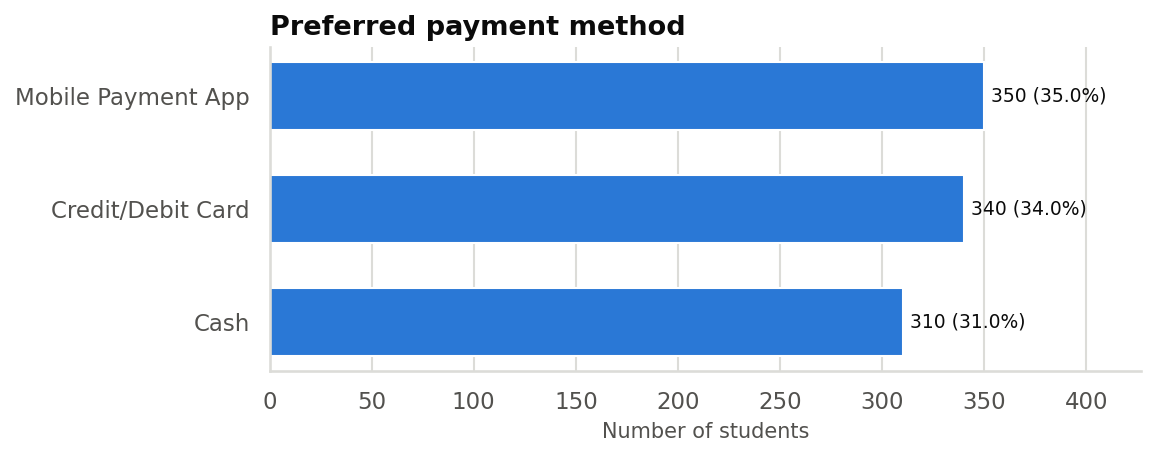

In [16]:
Image(filename=str(charts['05_payment_method_distribution']['file']))

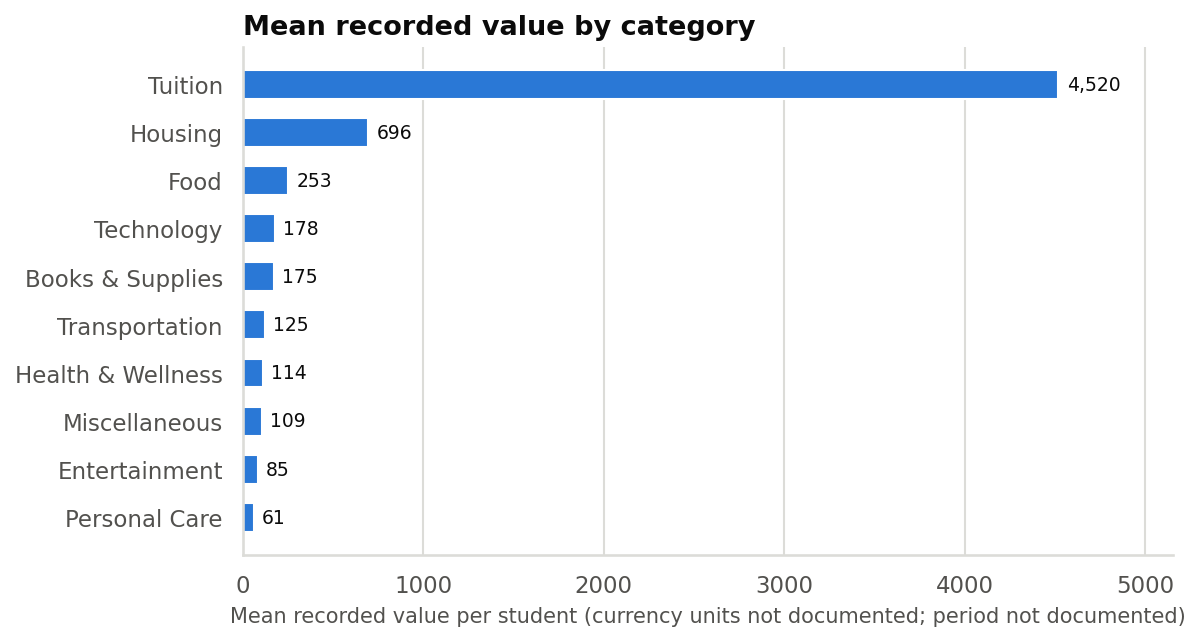

In [17]:
Image(filename=str(charts['08_category_mean_comparison']['file']))

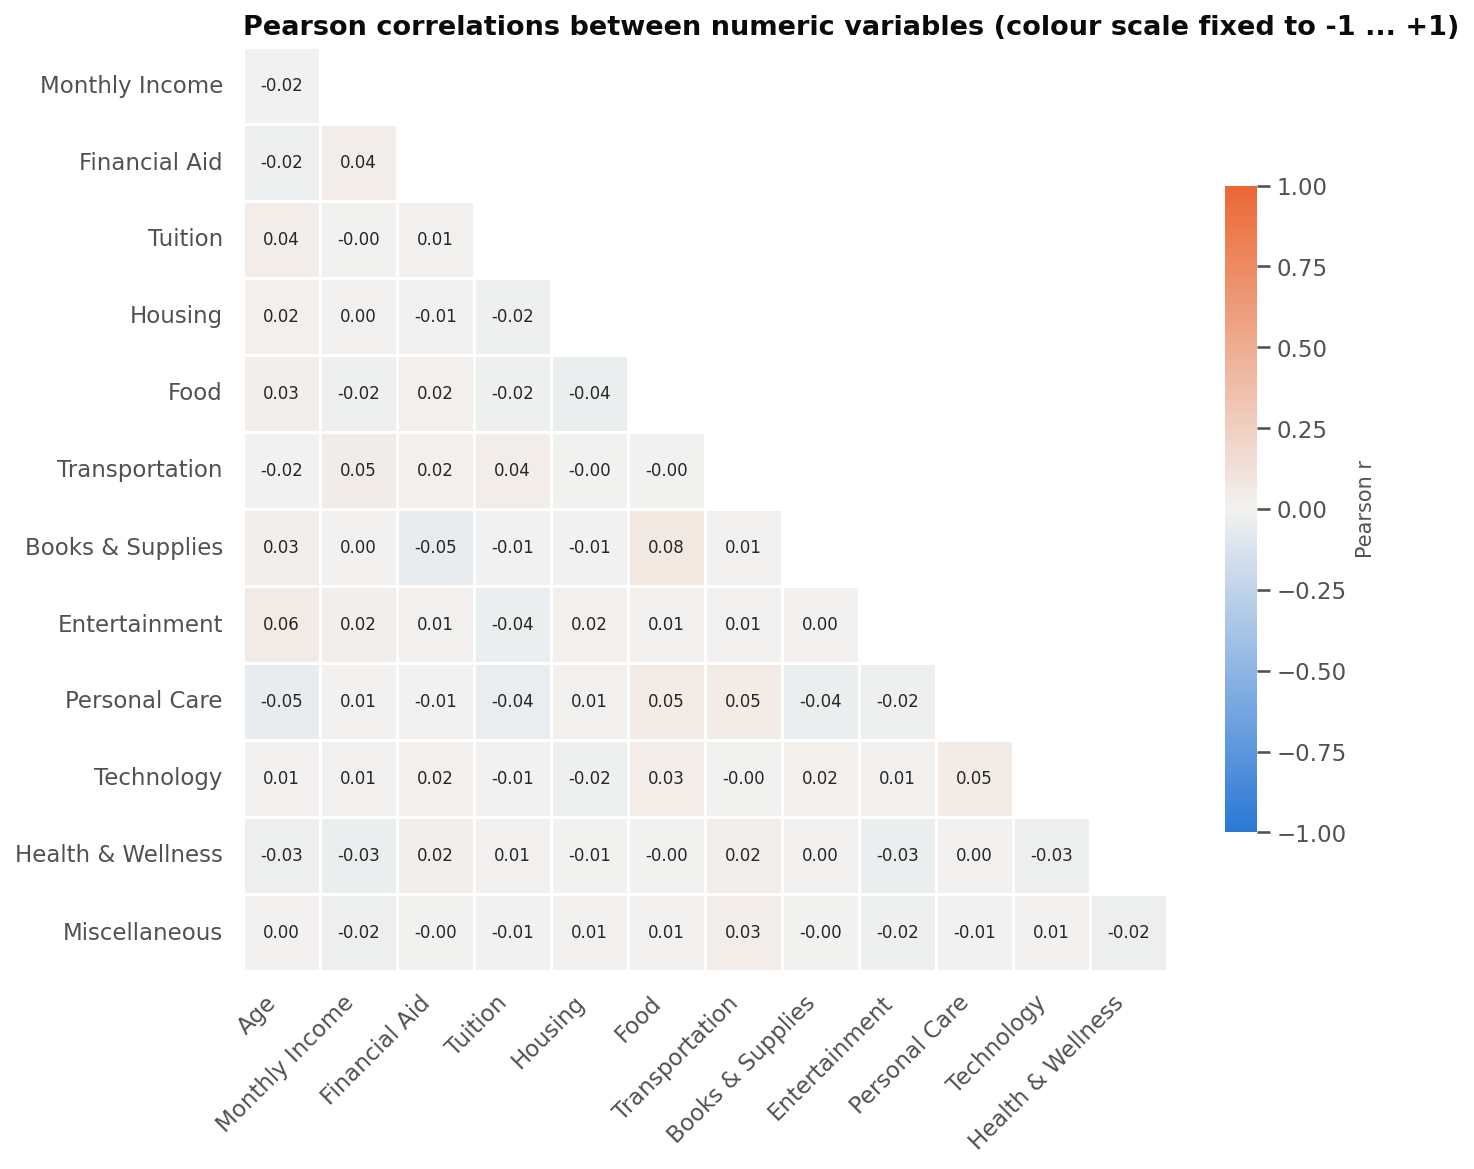

In [18]:
Image(filename=str(charts['14_correlation_heatmap']['file']))

## 11. DSA demonstration
Plain-Python algorithms checked against pandas (see `src/dsa_demo.py`).

In [19]:
from src import dsa_demo
d = dsa_demo.run_demo(df)
{k: v for k, v in d.items() if 'match' in k or 'found' in k}

{'frequencies_match_pandas': True,
 'min_max_match_pandas': True,
 'sort_matches_builtin': True,
 'sort_matches_pandas': True,
 'linear_search_matches_pandas': True,
 'binary_search_found': True}

In [20]:
dsa_demo.insertion_sort(list(df[data_loader.EXPENSE_COLUMNS].mean().items()), descending=True)

[('tuition', 4520.395),
 ('housing', 696.006),
 ('food', 252.642),
 ('technology', 178.304),
 ('books_supplies', 174.761),
 ('transportation', 124.637),
 ('health_wellness', 114.31),
 ('miscellaneous', 108.91),
 ('entertainment', 84.814),
 ('personal_care', 60.699)]

## 12. Conclusion
The data is structurally clean. Distributions are nearly flat, correlations are near zero and no group difference survives correction. Income and expense columns cannot be put on a common period. See `reports/project_report.md` for the full write-up.